# Module 03 — Wednesday: ML Workshop

**Platform:** Jupyter Notebook or Google Colab. **Method:** understand → run → inspect → practice.

The dataset is synthetic and only for training. The same notebook can run on either platform. Run the setup once, then execute cells from top to bottom.

## New library: scikit-learn (`sklearn`)
**What is it?** A Python machine-learning library that provides algorithms, train/test splitting, preprocessing and evaluation. You installed `numpy` and `pandas` in Module 2; now add **scikit-learn**.

**Install in either Jupyter or Google Colab (run this in a notebook cell only if necessary):**
```python
pip install scikit-learn
```
**Install from a computer terminal:** `python -m pip install -U scikit-learn`.

**Important:** We *install* `scikit-learn`, but we *import* `sklearn`. `sklearn.model_selection` contains data-splitting functions; `sklearn.tree` contains decision trees; `sklearn.dummy` contains baselines; `sklearn.metrics` contains evaluation functions. We use `.fit()` to learn and `.predict()` to produce predictions.


In [ ]:
import sklearn  # Load the package so we can inspect its installed version.
from sklearn.tree import DecisionTreeClassifier  # Import one ML algorithm.
from sklearn.model_selection import train_test_split  # Import a splitting tool.
print("scikit-learn version:", sklearn.__version__)  # Check installation.
print("Decision tree class:", DecisionTreeClassifier.__name__)  # Confirm import.

**Line-by-line code walkthrough**

- `import sklearn  # Load the package so we can inspect its installed version.` — Load the package so we can inspect its installed version.
- `from sklearn.tree import DecisionTreeClassifier  # Import one ML algorithm.` — Import one ML algorithm.
- `from sklearn.model_selection import train_test_split  # Import a splitting tool.` — Import a splitting tool.
- `print("scikit-learn version:", sklearn.__version__)  # Check installation.` — Check installation.
- `print("Decision tree class:", DecisionTreeClassifier.__name__)  # Confirm import.` — Confirm import.

## Setup — common imports and dataset

If `student_learning.csv` is in your working directory, use it. Otherwise, generate a small synthetic practice dataset so that **the notebook still runs** on both Jupyter and Colab.

In [ ]:
import pandas as pd  # Create and work with DataFrames.
import numpy as np  # Work with numerical data.
from pathlib import Path  # Work with file paths on any OS.
try:
    path = Path("student_learning.csv")  # Assign the resulting value to this variable for later use.
    df = pd.read_csv(path)  # Read the CSV file into a Pandas DataFrame.
    print("Dataset shape:", df.shape)  # Display the computed value or model result.
    print(df.head(3).to_string(index=False))  # Display the computed value or model result.
except FileNotFoundError:
    print("Stuents_learning.CSV file not found.")

## Our safe classification setup

We predict `passed` using information available before the final result. We **exclude** `final_score` because using the final outcome to predict passing would leak the answer.

In [ ]:
from sklearn.model_selection import train_test_split  # Import the functions or models needed for this step.
num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
X = df.drop(columns=["passed", "final_score"])  # Create a new table without the specified columns or rows.
y = df["passed"]  # Assign the resulting value to this variable for later use.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)  # Display the computed value or model result.

**Line-by-line code walkthrough**

- `from sklearn.model_selection import train_test_split` — Import the functions or models needed for this step.
- `num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]` — Assign the resulting value to this variable for later use.
- `X = df.drop(columns=["passed", "final_score"])` — Create a new table without the specified columns or rows.
- `y = df["passed"]` — Assign the resulting value to this variable for later use.
- `X_train, X_test, y_train, y_test = train_test_split(` — Split features and labels into matching training and test groups.
- `X, y, test_size=0.20, random_state=42, stratify=y` — Assign the resulting value to this variable for later use.
- `print("Training:", X_train.shape, "Testing:", X_test.shape)` — Display the computed value or model result.

## Lesson 01 — AI, ML and Deep Learning

**What it means:** Artificial intelligence is the broad goal of building systems that can perform intelligent tasks. Machine learning is one way to achieve that goal by learning from data.

**Why it is useful:** Deep learning is a type of ML that uses multi-layer neural networks. We first learn simple tabular ML before moving to neural networks in Module 4.

**Real situation:** A school predicts whether a student may need extra support using attendance and study activity, instead of writing hundreds of manual if-statements.

**Important terms:** **AI:** The broad field of intelligent systems; **ML:** Algorithms learn patterns from examples; **DL:** ML using multiple neural-network layers

**Workflow:** Identify a useful problem → Collect past examples → Learn patterns from data → Predict new cases

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [30]:
import pandas as pd  # Import the Python package used in the example.
from sklearn.tree import DecisionTreeClassifier  # Import the functions or models needed for this step.
X = [[1], [2],[4],[6] ,[9], [10]]  # Hours
y = [0, 0,0,0, 1, 1]  # Pass or fail
model = DecisionTreeClassifier(random_state=42)  # Assign the resulting value to this variable for later use.
model.fit(X, y)  # Fit the estimator using the provided training examples.
print(model.predict([[25]]))  # Display the computed value or model result.

[1]


**How to interpret the result:** The output is one predicted class: 0 (fail) or 1 (pass). The model learned a simple dividing rule from four examples, not a guarantee about real students.

**Common mistake:** Do not confuse learning a pattern with understanding why a student succeeds. Tiny datasets are for explanation, not real decisions.

1. you won an iphone    spam    1
2. you have class to attend     0
3. urgent message to respond about meeting 0
4. share this link and get a kfc deal for free 1

attachment 
this email is from PSEB for enrollment  0
you won 100k from Benazir Income support 1

### Instructor solution and explanation

Example 1: spam detection - email text → spam/not spam. 
Example 2: house pricing - size and location → predicted price.


## Lesson 02 — How a Machine Learning Project Works

**What it means:** A machine-learning workflow begins with a useful prediction question, not with importing an algorithm. Each step protects the quality of the final result.

**Why it is useful:** A working model is only useful if its input is reliable, its evaluation is fair, and someone can repeat its predictions on new records.

**Real situation:** Predict passing before the final exam. Inputs can include study hours and attendance. Final exam score is unavailable when the prediction is needed.

**Important terms:** **Question:** The decision supported by a prediction; **Dataset:** Examples represented by rows and columns; **Metric:** A number used to assess model performance

**Workflow:** Define the target → Inspect and split data → Train baseline and models → Evaluate; save; use

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [31]:
import pandas as pd  # Import the Python package used in the example.
df = pd.read_csv("student_learning.csv")  # Read the CSV file into a Pandas DataFrame.
print("Rows:", len(df))  # Display the computed value or model result.
print("Columns:", list(df.columns))  # Display the computed value or model result.
print(df.head(2))  # Display the computed value or model result.

Rows: 280
Columns: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method', 'final_score', 'passed']
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   
1            4.4          61               0          6.0        video   

   final_score  passed  
0           48       0  
1           50       0  


**Line-by-line code walkthrough**

- `import pandas as pd` — Import the Python package used in the example.
- `df = pd.read_csv("student_learning.csv")` — Read the CSV file into a Pandas DataFrame.
- `print("Rows:", len(df))` — Display the computed value or model result.
- `print("Columns:", list(df.columns))` — Display the computed value or model result.
- `print(df.head(2))` — Display the computed value or model result.

**How to interpret the result:** A table preview lets us verify columns before modeling. Later we will split records, fit models and compare predictions against known answers.

**Common mistake:** Training before checking the target can solve the wrong problem. Always define what will be predicted and when the inputs are available.

### Student practice

Write one prediction question for student data and choose a suitable metric.

Write your answer in a new code cell. Explain the result in one sentence.

## Lesson 03 — Rows, Features and Target

**What it means:** A row is one observation. A feature is an input column the model may use; the target is the answer the model tries to predict.

**Why it is useful:** Separating features (X) and target (y) prevents accidentally giving the correct answer to the model. Inputs must exist at prediction time.

**Real situation:** One row represents a student. Features: hours_studied, attendance, practice_tests, sleep_hours, study_method. Target: passed.

**Important terms:** **Sample:** One student or one record; **X / features:** Input columns used to make predictions; **y / target:** Correct value we hope to predict

**Workflow:** Choose target column → Remove target from X → Check feature names → Inspect X and y shapes

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [35]:
df = pd.read_csv("student_learning.csv")  # Read the CSV file into a Pandas DataFrame.
y = df["passed"]  # Correct answers
X = df.drop(columns=["passed", "final_score"])  # Create a new table without the specified columns or rows.
print("X:", X.shape)  # Display the computed value or model result.
print("y:", y.shape)  # Display the computed value or model result.
#print(df)
print(y)

X: (280, 5)
y: (280,)
0      0
1      0
2      1
3      0
4      0
      ..
275    0
276    0
277    0
278    1
279    1
Name: passed, Length: 280, dtype: int64


**Line-by-line code walkthrough**

- `df = pd.read_csv("student_learning.csv")` — Read the CSV file into a Pandas DataFrame.
- `y = df["passed"]  # Correct answers` — Correct answers
- `X = df.drop(columns=["passed", "final_score"])` — Create a new table without the specified columns or rows.
- `print("X:", X.shape)` — Display the computed value or model result.
- `print("y:", y.shape)` — Display the computed value or model result.

**How to interpret the result:** With 280 rows, X has 280 rows and 5 columns; y has 280 answers. The excluded final_score would reveal the pass/fail outcome.

**Common mistake:** Never include passed or final_score as an input when predicting passed. That is target leakage, not model intelligence.

### Student practice

Which columns are features if the target is final_score? What changes?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Use y = df["final_score"] and X = df.drop(columns=["final_score", "passed"]). Both outcome columns must be excluded.


**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Target is a numerical result; exclude both outcome columns.
y_reg = df["final_score"]  # Assign the resulting value to this variable for later use.
X_reg = df.drop(columns=["final_score", "passed"])  # Create a new table without the specified columns or rows.
print("Features:", list(X_reg.columns))  # Display the computed value or model result.
print("Shape:", X_reg.shape, y_reg.shape)  # Display the computed value or model result.

## Lesson 04 — Supervised vs Unsupervised Learning

**What it means:** Supervised learning uses labeled examples, such as each student having a known pass/fail result. Unsupervised learning finds patterns without known labels.

**Why it is useful:** Supervised tasks include classification (a category) and regression (a number). Clustering is a common unsupervised task and comes later.

**Real situation:** Predicting passed (0 or 1) is classification. Predicting final_score (0–100) is regression. Grouping similar study patterns is clustering.

**Important terms:** **Classification:** Predict a category such as Yes or No; **Regression:** Predict a numerical value; **Clustering:** Find similar groups without labels

**Workflow:** Look at the outcome → Is an answer labeled? → Category or number? → Choose task and metric

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [36]:
print("Pass labels:", df["passed"].unique())  # Display the computed value or model result.
print("Score type:", df["final_score"].dtype)  # Display the computed value or model result.
print(df["passed"].value_counts())  # Display the computed value or model result.
print(df["final_score"].describe().round(1))  # Display the computed value or model result.

Pass labels: [0 1]
Score type: int64
passed
0    157
1    123
Name: count, dtype: int64
count    280.0
mean      58.2
std       15.6
min       15.0
25%       47.8
50%       59.0
75%       69.2
max       94.0
Name: final_score, dtype: float64


**How to interpret the result:** If target values are 0 and 1, predict categories with a classifier. A continuous score is a regression target. The same dataset can support different tasks.

**Common mistake:** The type of a number alone does not decide the task: 0/1 is numeric in storage but still represents categories.

### Student practice

Classify the tasks: predicting temperature, detecting fraud, grouping customers, predicting exam grade A/B/C.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Temperature = regression; fraud = classification; customer grouping = clustering; A/B/C grade = classification.

.

## Lesson 05 — Train, Validation and Test Sets

**What it means:** Training data teaches the model. Validation data helps choose models/settings. Test data estimates performance on unseen examples after choices are made.

**Why it is useful:** If we train and test on the same rows, the score may be unrealistically high. Splitting is a basic protection against memorization.

**Real situation:** For 280 records, a 20% test split gives roughly 224 training and 56 test rows. A separate validation split is useful when tuning.

**Important terms:** **Train set:** Used to learn model parameters; **Validation set:** Used to choose model settings; **Test set:** Reserved for final honest evaluation

**Workflow:** Choose features and target → Split before preprocessing → Fit on train only → Score untouched test

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [38]:
from sklearn.model_selection import train_test_split  # Import the functions or models needed for this step.
X = df.drop(columns=["passed", "final_score"])  # Create a new table without the specified columns or rows.
y = df["passed"]  # Assign the resulting value to this variable for later use.
X_train, X_test, y_train, y_test = (
    train_test_split(X, y, test_size=0.25,
                     random_state=42, stratify=y))  # Assign the resulting value to this variable for later use.
print(X_train.shape,X_test.shape)
print(len(X_train), len(X_test))  # Display the computed value or model result.

(210, 5) (70, 5)
210 70


**How to interpret the result:** test_size=0.20 reserves about one fifth of rows. random_state makes the split repeatable; stratify maintains similar pass/fail proportions.

**Common mistake:** Do not calculate a scaler mean, fill missing data or select features using the entire dataset before splitting.

### Student practice

Change the test fraction to 25%. How many rows belong to each group?

Write your answer in a new code cell. Explain the result in one sentence.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [39]:
# Reserve one quarter of the dataset for an honest test.
from sklearn.model_selection import train_test_split  # Import the functions or models needed for this step.
a, b, c, d = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print("Training:", len(a), "Testing:", len(b))  # Display the computed value or model result.

Training: 210 Testing: 70


## Lesson 06 — Data Leakage and Fair Evaluation

**What it means:** Data leakage happens when training uses information that would not be available for a real future prediction or that comes from the held-out test data.

**Why it is useful:** Leakage may create very impressive evaluation scores but fails when the model is used in real life. It often comes from target-derived columns or early preprocessing.

**Real situation:** If passed is determined from final_score, including final_score as a feature makes predictions unrealistically easy even though the score is unknown before exams.

**Important terms:** **Target leakage:** Inputs contain the answer or future facts; **Split leakage:** Test data influences learned processing; **Fair evaluation:** Only evaluate on unseen, untouched examples

**Workflow:** Define prediction time → List available inputs → Split train and test → Fit every step on train

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [40]:
unsafe = ["hours_studied", "final_score"]  # Assign the resulting value to this variable for later use.
safe = ["hours_studied", "attendance"]  # Assign the resulting value to this variable for later use.
print("Leaky:", unsafe)  # Display the computed value or model result.
print("Available early:", safe)  # Display the computed value or model result.
X_safe = df.drop(
    columns=["passed", "final_score"])  # Assign the resulting value to this variable for later use.

Leaky: ['hours_studied', 'final_score']
Available early: ['hours_studied', 'attendance']


**How to interpret the result:** This example deliberately excludes final_score. The correct feature list depends on what information is actually available when the prediction is made.

**Common mistake:** A 99% score is not proof of a useful model. Ask whether the features contain the outcome or knowledge from the future.

### Student practice

Why is using final_score to predict passed a problem if final_score is recorded after the exam?

Write your answer in a new code cell. Explain the result in one sentence.

## Lesson 07 — Baselines and Your First Classifier

**What it means:** A baseline is a deliberately simple prediction strategy, such as always predicting the most common class. Better models should improve on it fairly.

**Why it is useful:** The first scikit-learn model uses fit() to learn from labeled training data and predict() to make predictions on test records.

**Real situation:** Our dataset contains both passing and failing records. Compare a majority-class baseline against a small decision tree.

**Important terms:** **fit(X, y):** Learn from labeled training examples; **predict(X):** Return predictions for unseen rows; **score(X, y):** Compute the estimator default metric

**Workflow:** Split and inspect target → Train majority baseline → Train a small tree → Compare both test scores

In [ ]:
# Import the baseline classifier from Scikit-learn.
from sklearn.dummy import DummyClassifier
# Import the Decision Tree classification algorithm.
from sklearn.tree import DecisionTreeClassifier
# Select four numerical features from the student dataset.
num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
# Create a baseline that always predicts the most common class.
base = DummyClassifier(strategy="most_frequent")
# Create a Decision Tree with a maximum depth of 3.
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
# Fit the baseline using training labels.
base.fit(X_train[num], y_train)
# Train the Decision Tree to learn patterns in student data.
tree.fit(X_train[num], y_train)
# Evaluate baseline accuracy on the test dataset.
print("Baseline:", round(base.score(X_test[num], y_test), 3))
# Evaluate Decision Tree accuracy on the same test dataset.
print("Tree:", round(tree.score(X_test[num], y_test), 3))

Baseline: 0.557
Tree: 0.729


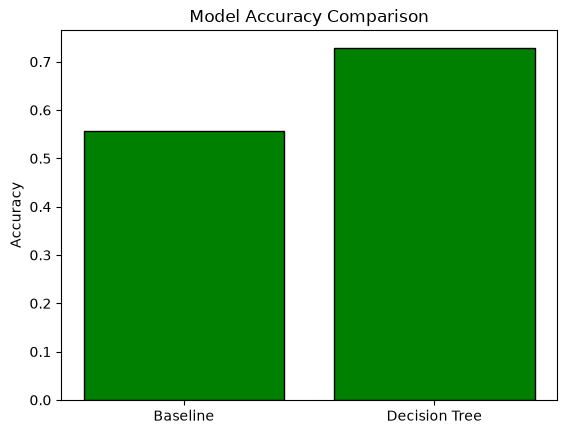

In [46]:
import matplotlib.pyplot as plt

# Get accuracy of both models
base_score = base.score(X_test[num], y_test)
tree_score = tree.score(X_test[num], y_test)
# Create a bar graph
plt.bar(["Baseline","Decision Tree"],[base_score, tree_score],color="green",edgecolor="black")
# Add title and labels
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
# Display the graph
plt.show()

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

**Line-by-line code walkthrough**

- `from sklearn.dummy import DummyClassifier` — Import the functions or models needed for this step.
- `from sklearn.tree import DecisionTreeClassifier` — Import the functions or models needed for this step.
- `base = DummyClassifier(strategy="most_frequent")` — Assign the resulting value to this variable for later use.
- `base.fit(X_train, y_train)` — Fit the estimator using the provided training examples.
- `tree = DecisionTreeClassifier(max_depth=3,` — Assign the resulting value to this variable for later use.
- `random_state=42)` — Assign the resulting value to this variable for later use.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Compare a simple guess with a trained tree, fairly.
from sklearn.dummy import DummyClassifier  # Import the functions or models needed for this step.
from sklearn.tree import DecisionTreeClassifier  # Import the functions or models needed for this step.
cols = ["hours_studied", "attendance"]  # Assign the resulting value to this variable for later use.
b = DummyClassifier(strategy="most_frequent")  # Assign the resulting value to this variable for later use.
t = DecisionTreeClassifier(max_depth=3, random_state=42)  # Assign the resulting value to this variable for later use.
for name, model in [("Baseline", b), ("Tree", t)]:  # Repeat the following indented statements for each value.
    model.fit(X_train[cols], y_train)  # Fit the estimator using the provided training examples.
    print(name, round(model.score(X_test[cols], y_test), 3))  # Display the computed value or model result.

**Line-by-line code walkthrough**

- `from sklearn.dummy import DummyClassifier` — Import the functions or models needed for this step.
- `from sklearn.tree import DecisionTreeClassifier` — Import the functions or models needed for this step.
- `cols = ["hours_studied", "attendance"]` — Assign the resulting value to this variable for later use.
- `b = DummyClassifier(strategy="most_frequent")` — Assign the resulting value to this variable for later use.
- `t = DecisionTreeClassifier(max_depth=3, random_state=42)` — Assign the resulting value to this variable for later use.
- `for name, model in [("Baseline", b), ("Tree", t)]:` — Repeat the following indented statements for each value.
- `model.fit(X_train[cols], y_train)` — Fit the estimator using the provided training examples.
- `print(name, round(model.score(X_test[cols], y_test), 3))` — Display the computed value or model result.

## Wrap-up

Which part of the workflow would you explain to a beginner? What could go wrong if we leaked target information or judged models on training data?